In [48]:
#split the dataset into training and testing sets
from sklearn.model_selection import train_test_split as tts

#used to scale the input features
from sklearn.preprocessing import StandardScaler as ss

#K-Nearest Neighbours regression model
from sklearn.neighbors import KNeighborsRegressor as knr

#test different values of k using cross-validation
from sklearn.model_selection import GridSearchCV

#used to evaluate the final model
from sklearn.metrics import mean_squared_error as ms_error, r2_score

# Used for calculating the square root when finding RMSE
import numpy as np

# Used for creating a results table
import pandas as pd

In [ ]:
dataset = pd.read_csv("data/Hussain_Replication/Aggregated_Configurations.csv")





def extract_site_composition(ions, coefficients, group):

    # Start by giving every element at this site a value of 0
    # If an element is not present in a particular perovskite,
    # its value will stay as 0
    composition = {
        element: 0.0 for element in group
    }

    # If either the ion column or coefficient column is missing,
    # return the default values of 0
    if pd.isna(ions) or pd.isna(coefficients):
        return composition

    # Split the ion string at each semicolon
    # Example:
    # "Cs; FA; MA" becomes ["Cs", "FA", "MA"]
    ion_list = [
        ion.strip()
        for ion in str(ions).split(";")
    ]

    # Split the coefficient string at each semicolon
    # and convert each value into a number
    # Example:
    # "0.05; 0.85; 0.15" becomes [0.05, 0.85, 0.15]
    coefficient_list = [
        float(value.strip())
        for value in str(coefficients).split(";")
    ]


    for ion, coefficient in zip(ion_list, coefficient_list):

        # Only save species that are expected at this site
        if ion in composition:
            composition[ion] = coefficient

    # Return the finished numerical composition for this site
    return composition





# --------------------------------------------------
# 2. DEFINE THE POSSIBLE SPECIES AT EACH SITE
# --------------------------------------------------

# A-site species
# MA and FA are molecular ions, but they are treated as
# individual composition features in the ML model
a_site_species = [
    "Cs",
    "FA",
    "MA"
]

# B-site species
b_site_species = [
    "Pb",
    "Sn"
]

# X-site species
# Your dataset calls this the "c_ions" column
x_site_species = [
    "Cl",
    "Br",
    "I"
]



# --------------------------------------------------
# 3. EXTRACT THE A-SITE COMPOSITION
# --------------------------------------------------

# Apply the function to every row of the dataset
a_composition = dataset.apply(
    lambda row: extract_site_composition(
        row["Perovskite_composition_a_ions"],
        row["Perovskite_composition_a_ions_coefficients"],
        a_site_species
    ),
    axis=1
)

# Convert the resulting dictionaries into normal DataFrame columns
a_composition = pd.DataFrame(
    a_composition.tolist(),
    index=dataset.index
)



# --------------------------------------------------
# 4. EXTRACT THE B-SITE COMPOSITION
# --------------------------------------------------

b_composition = dataset.apply(
    lambda row: extract_site_composition(
        row["Perovskite_composition_b_ions"],
        row["Perovskite_composition_b_ions_coefficients"],
        b_site_species
    ),
    axis=1
)

# Convert the results into DataFrame columns
b_composition = pd.DataFrame(
    b_composition.tolist(),
    index=dataset.index
)






# --------------------------------------------------
# 5. EXTRACT THE X-SITE COMPOSITION
# --------------------------------------------------

x_composition = dataset.apply(
    lambda row: extract_site_composition(
        row["Perovskite_composition_c_ions"],
        row["Perovskite_composition_c_ions_coefficients"],
        x_site_species
    ),
    axis=1
)

# Convert the results into DataFrame columns
x_composition = pd.DataFrame(
    x_composition.tolist(),
    index=dataset.index
)






# Join the A-, B-, and X-site numerical features together
composition_features = pd.concat(
    [
        a_composition,
        b_composition,
        x_composition
    ],
    axis=1
)

# Display the first few rows
display(composition_features.head())



# Add the extracted numerical composition features
# onto the original dataset
dataset = pd.concat(
    [
        dataset,
        composition_features
    ],
    axis=1
)

# Check that the new columns are now present
print(dataset.columns.tolist())

,Cs,FA,MA,Pb,Sn,Cl,Br,I
0,0.005,0.0,0.0,0.995,0.0,0.0,3.0,0.0
1,1.000,0.0,0.0,1.000,0.0,0.0,3.0,0.0
2,1.000,0.0,0.0,1.000,0.0,0.0,3.0,0.0
3,1.000,0.0,0.0,1.000,0.0,0.0,3.0,0.0
4,1.000,0.0,0.0,1.000,0.0,0.0,3.0,0.0


['Perovskite_composition_a_ions', 'Perovskite_composition_a_ions_coefficients', 'Perovskite_composition_b_ions', 'Perovskite_composition_b_ions_coefficients', 'Perovskite_composition_c_ions', 'Perovskite_composition_c_ions_coefficients', 'Cell_architecture', 'Substrate_stack_sequence', 'ETL_stack_sequence', 'HTL_stack_sequence', 'Backcontact_stack_sequence', 'n_records', 'mean_PCE', 'median_PCE', 'std_PCE', 'mean_band_gap', 'median_band_gap', 'std_band_gap', 'mean_Jsc', 'std_Jsc', 'mean_Voc', 'std_Voc', 'mean_FF', 'std_FF', 'Cs', 'FA', 'MA', 'Pb', 'Sn', 'Cl', 'Br', 'I']


In [50]:
#inputs
x = dataset [[
        "Cs",
        "MA",
        "FA",
        "Pb",
        "Sn",
        "Br",
        "I",
        "Cl"
    ]
]

y_mean = dataset["mean_band_gap"]
y_median = dataset["median_band_gap"]

#datasplit 4 train and test
xtrain,xtest,ytrain_mean,ytest_mean = tts(x,y_mean,test_size=0.2,random_state=67)
xtrain,xtest,ytrain_median,ytest_median = tts(x,y_median,test_size=0.2,random_state=67)

In [51]:
scaler=ss()
xtrain_scaled = scaler.fit_transform(xtrain)
xtest_scaled = scaler.transform(xtest)

In [52]:
#find best k
knn=knr()
ktest = {"n_neighbors":[3,5,7,9,11,15,20]}

grid_knn = GridSearchCV(knn, ktest, cv=5, scoring="neg_root_mean_squared_error")

grid_knn.fit(xtrain_scaled,ytrain_mean)

bestk_mean = grid_knn.best_params_["n_neighbors"]
print("best k mean=", bestk_mean)

knn=knr()
ktest = {"n_neighbors":[3,5,7,9,11,15,20]}

grid_knn = GridSearchCV(knn, ktest, cv=5, scoring="neg_root_mean_squared_error")

grid_knn.fit(xtrain_scaled,ytrain_median)

bestk_median = grid_knn.best_params_["n_neighbors"]
print("best k median=", bestk_median)


best k mean= 3
best k median= 3


In [53]:
#calc errors
knn_final1 = knr(n_neighbors=bestk_mean)

knn_final1.fit(xtrain_scaled, ytrain_mean)
knn_pred1=knn_final1.predict(xtest_scaled)
knn_mse1 =ms_error(ytest_mean, knn_pred1)
knn_rmse1 = np.sqrt(knn_mse1)
knn_r2_1=r2_score(ytest_mean, knn_pred1)


knn_final2 = knr(n_neighbors=bestk_median)

knn_final2.fit(xtrain_scaled, ytrain_median)
knn_pred2=knn_final2.predict(xtest_scaled)
knn_mse2 =ms_error(ytest_median, knn_pred2)
knn_rmse2 = np.sqrt(knn_mse2)
knn_r2_2=r2_score(ytest_median, knn_pred2)


#display
print("KNN RMSE mean:", knn_rmse1, "KNN R^2 mean:", knn_r2_1, 
      "KNN RMSE median:", knn_rmse2,   "KNN R^2 median:", knn_r2_2)

#compare
knn_results = pd.DataFrame({"actual band gap mean:": ytest_mean, "predicted band gap mean:": knn_pred1, "actual band gap median:": ytest_median, "predicted band gap median:": knn_pred2})
display(knn_results.head())

KNN RMSE mean: 0.05278568300791143 KNN R^2 mean: 0.9437249051279313 KNN RMSE median: 0.05270930060596868 KNN R^2 median: 0.9445809356253185


,actual band gap mean:,predicted band gap mean:,actual band gap median:,predicted band gap median:
74,2.277000,2.271000,2.277,2.271000
127,1.608333,1.572964,1.609,1.573333
154,1.590000,1.630667,1.590,1.630667
546,1.600000,1.597271,1.600,1.600000
590,1.500000,1.597271,1.500,1.600000


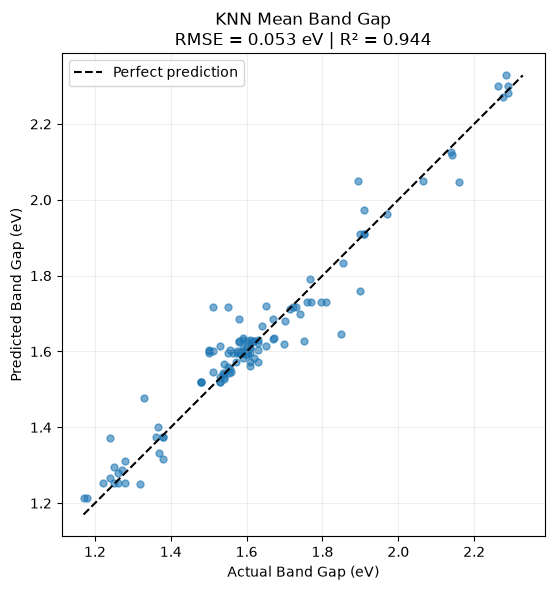

In [58]:
# Predicted vs Actual Band Gap - Mean KNN Model

import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))

# Scatter plot of actual vs predicted values
plt.scatter(ytest_mean, knn_pred1, alpha=0.6, s=25)

# Perfect prediction line
lower = min(ytest_mean.min(), knn_pred1.min())
upper = max(ytest_mean.max(), knn_pred1.max())
plt.plot([lower, upper], [lower, upper], "k--", label="Perfect prediction")

plt.xlabel("Actual Band Gap (eV)")
plt.ylabel("Predicted Band Gap (eV)")
plt.title(f"KNN Mean Band Gap\nRMSE = {knn_rmse1:.3f} eV | R² = {knn_r2_1:.3f}")
plt.gca().set_aspect("equal", adjustable="box")
plt.legend()
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [55]:
import pandas as pd
from pathlib import Path

results_file = Path("Data/Model_Comparison_Results.csv")
results_file.parent.mkdir(parents=True, exist_ok=True)

columns = [
    "Run ID",
    "Model",
    "Training Dataset",
    "Training Dataset Size",
    "Testing Dataset",
    "Testing Dataset Size",
    "Aggregation Method",
    "Prediction Target",
    "Model Parameters",
    "Evaluation Method",
    "RMSE",
    "R2"
]

def save_results(rows):

    # Load existing database
    if results_file.exists():
        database = pd.read_csv(results_file)
    else:
        database = pd.DataFrame(columns=columns)

    # Convert older column names
    database = database.rename(columns={
        "Run_ID": "Run ID",
        "Training_Dataset": "Training Dataset",
        "Training_Samples": "Training Dataset Size",
        "Testing_Dataset": "Testing Dataset",
        "Testing_Samples": "Testing Dataset Size",
        "Target": "Prediction Target",
        "Hyperparameter": "Model Parameters",
        "Test_RMSE": "RMSE",
        "Test_R2": "R2"
    })

    # Match the agreed database structure
    database = database.reindex(columns=columns)

    # Prepare incoming results
    new_results = pd.DataFrame(rows)
    new_results = new_results.reindex(columns=columns)

    # Replace results from previous runs
    database = database[
        ~database["Run ID"].isin(new_results["Run ID"])
    ]

    # Combine and save
    database = pd.concat(
        [database, new_results],
        ignore_index=True
    )

    database.to_csv(results_file, index=False)

    print("Results saved successfully.")
    print("Total recorded models:", len(database))

print("Updated saving function loaded.")


Updated saving function loaded.


In [56]:

save_results([
    {
        "Run ID": "KNN_600_Mean",
        "Model": "K Nearest Neighbours",
        "Training Dataset": "Aggregated",
        "Training Dataset Size": len(xtrain),
        "Testing Dataset": "Aggregated",
        "Testing Dataset Size": len(xtest),
        "Aggregation Method": "Mean",
        "Prediction Target": "Band Gap",
        "Model Parameters": f"k={bestk_mean}",
        "Evaluation Method": "80/20 Holdout",
        "RMSE": knn_rmse1,
        "R2": knn_r2_1
    },
    {
        "Run ID": "KNN_600_Median",
        "Model": "K Nearest Neighbours",
        "Training Dataset": "Aggregated",
        "Training Dataset Size": len(xtrain),
        "Testing Dataset": "Aggregated",
        "Testing Dataset Size": len(xtest),
        "Aggregation Method": "Median",
        "Prediction Target": "Band Gap",
        "Model Parameters": f"k={bestk_median}",
        "Evaluation Method": "80/20 Holdout",
        "RMSE": knn_rmse2,
        "R2": knn_r2_2
    }
])


Results saved successfully.
Total recorded models: 14
